# EconoCausal: Exploratory Data Analysis (EDA)

## Project Title
**Dynamic Pricing via Double Machine Learning**

## 1. Objective
The objective of this notebook is to explore the Online Retail II dataset and understand its structure, data quality, sales trends, quantity distribution, and product-level price variation.

## 2. Business Problem
Businesses need to understand how product prices relate to customer purchasing behavior. This analysis investigates the relationship between unit price and quantity purchased as a foundation for a later causal analysis.

## 3. Dataset Description
The dataset contains online retail transaction records, including invoice identifiers, product codes, quantities, invoice dates, unit prices, customer identifiers, and countries.

## 4. Analysis Plan
- Load and inspect the processed dataset.
- Examine missing values, duplicates, and numeric distributions.
- Analyze quantity and unit-price distributions.
- Explore monthly sales trends.
- Investigate product-level price variation.
- Assess the dataset's suitability for causal inference.

## 5. Important Limitation
A relationship between price and quantity does not, by itself, prove that price changes cause changes in demand. Potential confounders and data limitations must be assessed before fitting a Double Machine Learning model.

In [8]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

# Identify the project root
PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "Data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "Data" / "Processed"
REPORT_DIR = PROJECT_ROOT / "reports"

REPORT_DIR.mkdir(parents=True, exist_ok=True)

DATA_PATH = DATA_DIR / "online_retail_sales_initial.csv"

print("Project root:", PROJECT_ROOT)
print("Dataset path:", DATA_PATH)
print("Dataset exists:", DATA_PATH.exists())

Project root: c:\intern_project\econocausal-dml
Dataset path: c:\intern_project\econocausal-dml\Data\Processed\online_retail_sales_initial.csv
Dataset exists: True


## 1. Load the Dataset

The processed dataset contains positive-quantity, positive-price transaction lines. This initial filter helps us explore ordinary sales transactions separately from cancellations, returns, and invalid prices.

The original workbook should still be used when investigating data-quality issues that were excluded during preprocessing.

In [9]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}. "
        "Run scripts/process_online_retail.py first."
    )

df = pd.read_csv(
    DATA_PATH,
    parse_dates=["invoicedate"],
    low_memory=False
)

print("Number of rows:", f"{df.shape[0]:,}")
print("Number of columns:", df.shape[1])

display(df.head())

Number of rows: 1,041,670
Number of columns: 9


,invoice,stockcode,description,quantity,invoicedate,unit_price,customer_id,country,line_sales_value
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0


## 2. Dataset Structure

This section examines the dataset's dimensions, column names, data types, and descriptive statistics.

Understanding the data structure helps identify which variables may be useful for transaction analysis and future causal modeling.

In [10]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nDescriptive statistics:")
display(df.describe(include="all").T)

print("\nDate range:")
print("Start date:", df["invoicedate"].min())
print("End date:", df["invoicedate"].max())

print("\nUnique counts:")
for col in ["invoice", "stockcode", "customer_id", "country"]:
    if col in df.columns:
        print(f"{col}: {df[col].nunique():,}")

Column names:
['invoice', 'stockcode', 'description', 'quantity', 'invoicedate', 'unit_price', 'customer_id', 'country', 'line_sales_value']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1041670 entries, 0 to 1041669
Data columns (total 9 columns):
 #   Column            Non-Null Count    Dtype         
---  ------            --------------    -----         
 0   invoice           1041670 non-null  object        
 1   stockcode         1041670 non-null  object        
 2   description       1041670 non-null  object        
 3   quantity          1041670 non-null  int64         
 4   invoicedate       1041670 non-null  datetime64[ns]
 5   unit_price        1041670 non-null  float64       
 6   customer_id       805549 non-null   float64       
 7   country           1041670 non-null  object        
 8   line_sales_value  1041670 non-null  float64       
dtypes: datetime64[ns](1), float64(3), int64(1), object(4)
memory usage: 71.5+ MB

Descriptive statistics:


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
invoice,1041670,40077,537434,1350,NaN,NaN,NaN,NaN,NaN,NaN,NaN
stockcode,1041670,4917,85123A,5686,NaN,NaN,NaN,NaN,NaN,NaN,NaN
description,1041670,5399,WHITE HANGING HEART T-LIGHT HOLDER,5778,NaN,NaN,NaN,NaN,NaN,NaN,NaN
quantity,1041670.0,NaN,NaN,NaN,10.963458,1.0,1.0,3.0,10.0,80995.0,126.51499
invoicedate,1041670,NaN,NaN,NaN,2011-01-03 16:31:54.300440576,2009-12-01 07:45:00,2010-07-12 10:28:45,2010-12-07 15:33:00,2011-07-24 12:05:00,2011-12-09 12:50:00,NaN
unit_price,1041670.0,NaN,NaN,NaN,4.076683,0.001,1.25,2.1,4.13,25111.09,51.44773
customer_id,805549.0,NaN,NaN,NaN,15331.95497,12346.0,13982.0,15271.0,16805.0,18287.0,1696.737039
country,1041670,43,United Kingdom,958501,NaN,NaN,NaN,NaN,NaN,NaN,NaN
line_sales_value,1041670.0,NaN,NaN,NaN,20.133626,0.001,3.9,9.96,17.7,168469.6,203.116455



Date range:
Start date: 2009-12-01 07:45:00
End date: 2011-12-09 12:50:00

Unique counts:
invoice: 40,077
stockcode: 4,917
customer_id: 5,878
country: 43


## 3. Data Quality Assessment

Data quality checks help determine whether the processed dataset satisfies the assumptions required for descriptive analysis.

This section examines missing values, duplicate rows, non-positive quantities, non-positive prices, and missing invoice dates.

Because this dataset has already been filtered, these checks validate the processed data rather than fully describe the original workbook.

In [11]:
quality_report = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage": (df.isna().mean() * 100).round(2),
    "data_type": df.dtypes.astype(str)
})

display(quality_report)

print("Exact duplicate rows:", f"{df.duplicated().sum():,}")
print("Quantity <= 0:", f"{(df['quantity'] <= 0).sum():,}")
print("Unit price <= 0:", f"{(df['unit_price'] <= 0).sum():,}")
print("Missing invoice dates:", f"{df['invoicedate'].isna().sum():,}")

assert (df["quantity"] > 0).all(), "Unexpected non-positive quantity"
assert (df["unit_price"] > 0).all(), "Unexpected non-positive unit price"

print("\nPositive quantity and price checks passed.")

,missing_count,missing_percentage,data_type
invoice,0,0.00,object
stockcode,0,0.00,object
description,0,0.00,object
quantity,0,0.00,int64
invoicedate,0,0.00,datetime64[ns]
unit_price,0,0.00,float64
customer_id,236121,22.67,float64
country,0,0.00,object
line_sales_value,0,0.00,float64


Exact duplicate rows: 33,757
Quantity <= 0: 0
Unit price <= 0: 0
Missing invoice dates: 0

Positive quantity and price checks passed.


## 4. Quantity and Unit-Price Distributions

Histograms help reveal skewness, concentration, and extreme observations in transaction quantities and unit prices.

The first visualization displays the full distributions. A second visualization limits the displayed range to the 99th percentile to make the central portion easier to inspect.

The percentile-based plots are for visualization only; they do not remove observations from the dataset.

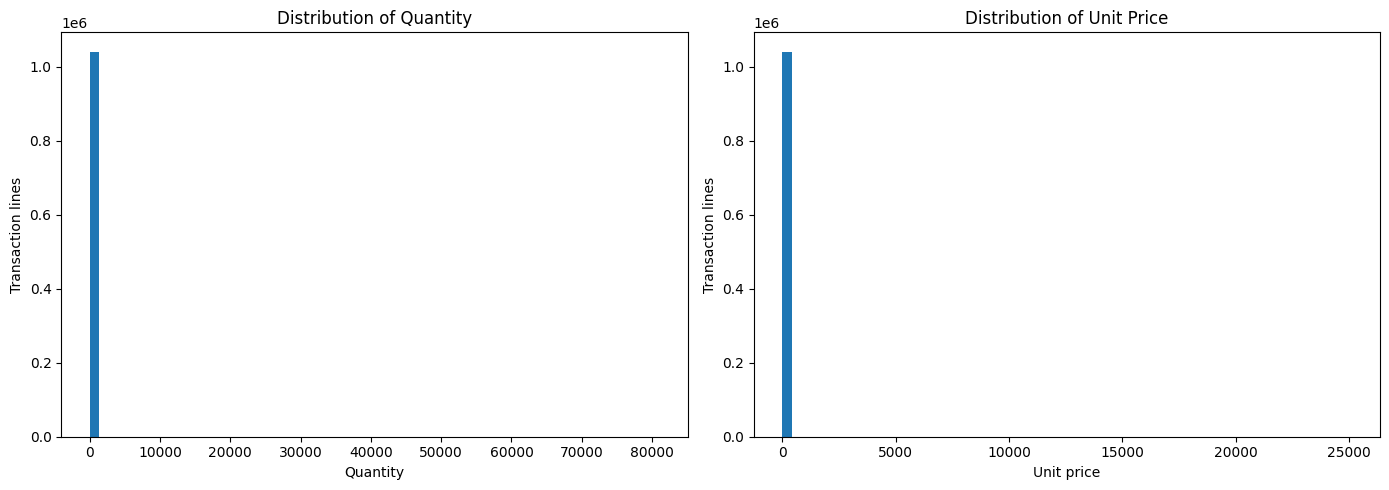

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df["quantity"], bins=60)
axes[0].set_title("Distribution of Quantity")
axes[0].set_xlabel("Quantity")
axes[0].set_ylabel("Transaction lines")

axes[1].hist(df["unit_price"], bins=60)
axes[1].set_title("Distribution of Unit Price")
axes[1].set_xlabel("Unit price")
axes[1].set_ylabel("Transaction lines")

plt.tight_layout()
plt.show()

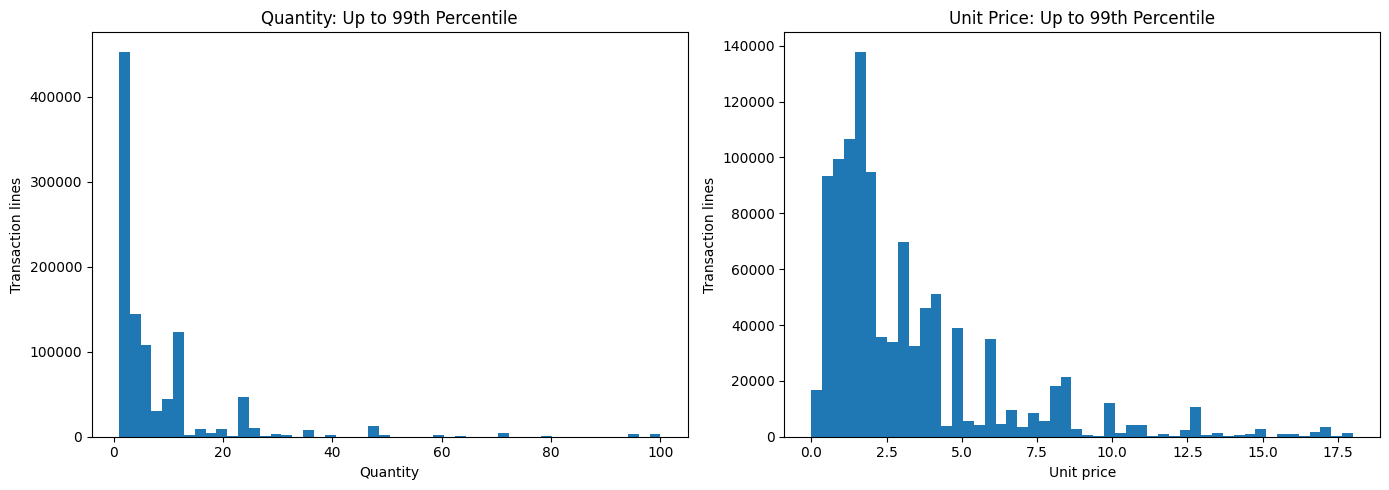

99th percentile quantity: 100.00
99th percentile unit price: 18.00


In [13]:
quantity_cap = df["quantity"].quantile(0.99)
price_cap = df["unit_price"].quantile(0.99)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(
    df.loc[df["quantity"] <= quantity_cap, "quantity"],
    bins=50
)
axes[0].set_title("Quantity: Up to 99th Percentile")
axes[0].set_xlabel("Quantity")
axes[0].set_ylabel("Transaction lines")

axes[1].hist(
    df.loc[df["unit_price"] <= price_cap, "unit_price"],
    bins=50
)
axes[1].set_title("Unit Price: Up to 99th Percentile")
axes[1].set_xlabel("Unit price")
axes[1].set_ylabel("Transaction lines")

plt.tight_layout()
plt.show()

print(f"99th percentile quantity: {quantity_cap:.2f}")
print(f"99th percentile unit price: {price_cap:.2f}")

## 5. Monthly Sales Trends

Monthly aggregation helps reveal changes in transaction activity, sales value, units sold, and unit prices over time.

The sales measure used here is the sum of positive transaction-line values in the processed dataset. It should not be interpreted as net revenue or profit because returns and cancellations were excluded during preprocessing.

,month,transaction_lines,unique_invoices,units_sold,gross_line_sales,average_unit_price,median_unit_price
0,2009-12-01,43957,1682,426981,825685.760,4.272373,2.57
1,2010-01-01,30638,1105,391525,652708.502,4.634179,2.51
2,2010-02-01,28281,1201,382781,553339.736,3.764568,2.10
3,2010-03-01,40364,1681,527401,833570.131,5.125525,2.10
4,2010-04-01,33268,1462,368198,681528.992,4.348378,2.10


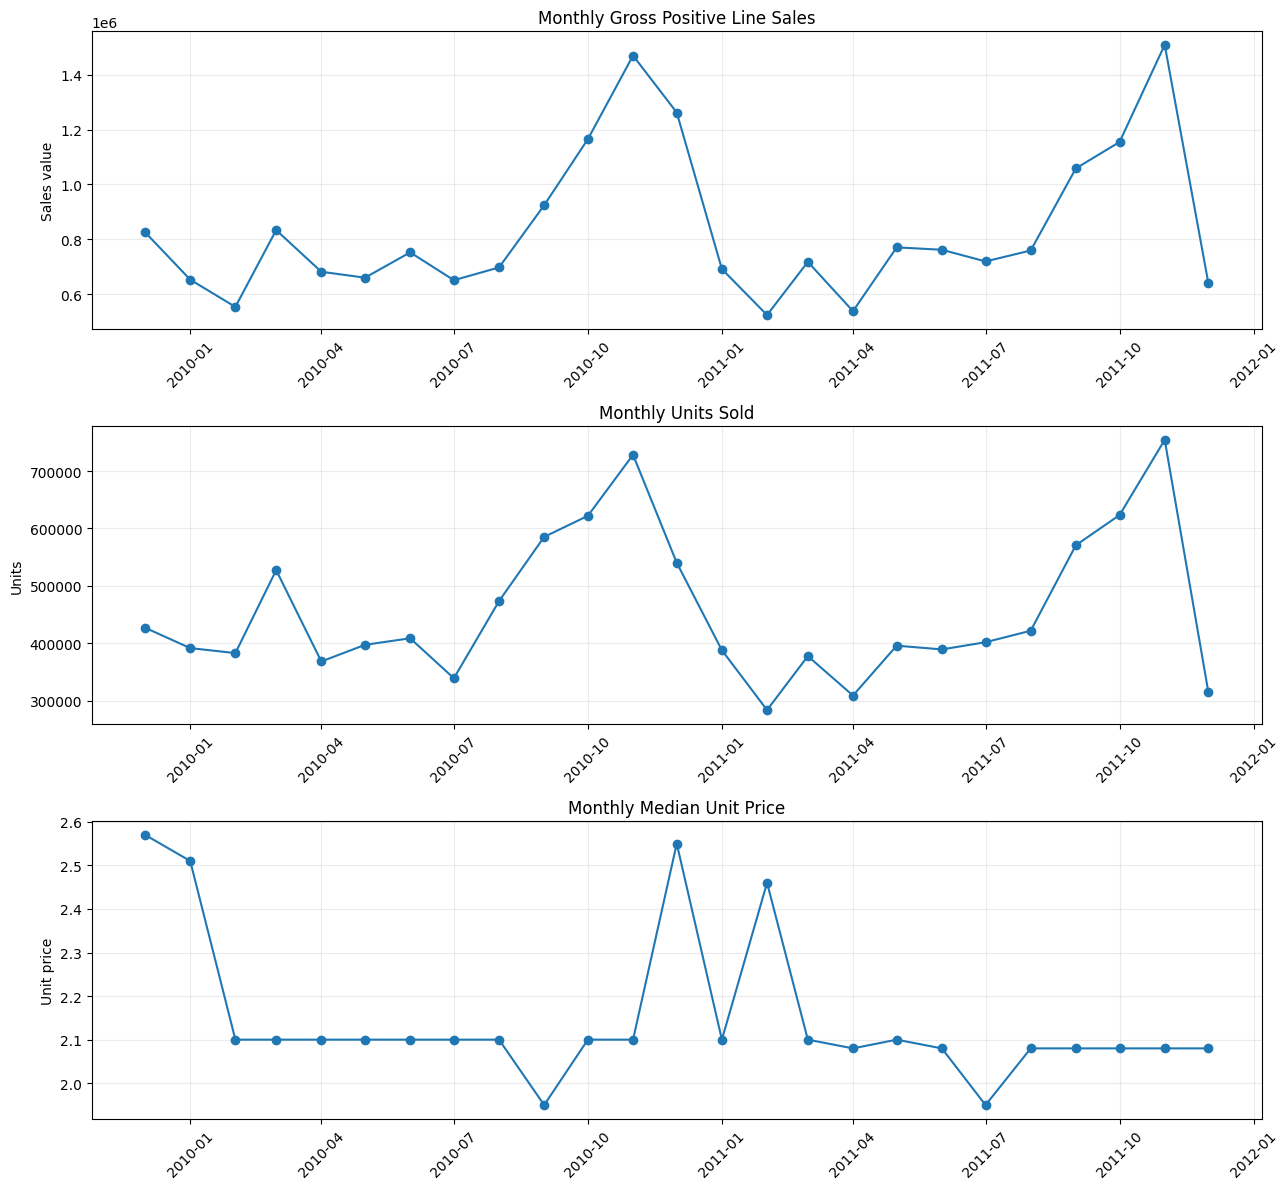

In [14]:
df["month"] = (
    df["invoicedate"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

monthly_summary = (
    df.groupby("month")
    .agg(
        transaction_lines=("invoice", "size"),
        unique_invoices=("invoice", "nunique"),
        units_sold=("quantity", "sum"),
        gross_line_sales=("line_sales_value", "sum"),
        average_unit_price=("unit_price", "mean"),
        median_unit_price=("unit_price", "median")
    )
    .reset_index()
)

display(monthly_summary.head())

fig, axes = plt.subplots(3, 1, figsize=(13, 12))

axes[0].plot(
    monthly_summary["month"],
    monthly_summary["gross_line_sales"],
    marker="o"
)
axes[0].set_title("Monthly Gross Positive Line Sales")
axes[0].set_ylabel("Sales value")

axes[1].plot(
    monthly_summary["month"],
    monthly_summary["units_sold"],
    marker="o"
)
axes[1].set_title("Monthly Units Sold")
axes[1].set_ylabel("Units")

axes[2].plot(
    monthly_summary["month"],
    monthly_summary["median_unit_price"],
    marker="o"
)
axes[2].set_title("Monthly Median Unit Price")
axes[2].set_ylabel("Unit price")

for ax in axes:
    ax.tick_params(axis="x", rotation=45)
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

## 6. Product-Level Price Variation

Dynamic pricing analysis requires examining whether the same product is observed at different prices.

This section calculates the number of transaction lines, unique observed prices, minimum and maximum prices, median price, and total quantity for each product code.

Observed price variation is a necessary exploratory signal, but it does not establish causal identification. Differences in dates, customers, countries, promotions, and other unobserved factors may explain the variation.

In [15]:
product_summary = (
    df.groupby("stockcode")
    .agg(
        transaction_lines=("unit_price", "size"),
        unique_prices=("unit_price", "nunique"),
        median_price=("unit_price", "median"),
        min_price=("unit_price", "min"),
        max_price=("unit_price", "max"),
        total_quantity=("quantity", "sum")
    )
    .reset_index()
)

product_summary["price_range"] = (
    product_summary["max_price"] - product_summary["min_price"]
)

eligible_products = product_summary[
    product_summary["transaction_lines"] >= 5
]

multiple_price_count = (
    eligible_products["unique_prices"] > 1
).sum()

print("Unique products:", f"{len(product_summary):,}")
print("Products with at least 5 transaction lines:",
      f"{len(eligible_products):,}")
print("Eligible products with multiple observed prices:",
      f"{multiple_price_count:,}")

display(
    eligible_products
    .sort_values("transaction_lines", ascending=False)
    .head(20)
)

Unique products: 4,917
Products with at least 5 transaction lines: 4,502
Eligible products with multiple observed prices: 4,256


,stockcode,transaction_lines,unique_prices,median_price,min_price,max_price,total_quantity,price_range
4301,85123A,5686,14,2.95,1.90,6.04,96147,4.14
4273,85099B,4124,14,1.95,1.65,5.06,98349,3.41
1638,22423,4061,13,12.75,4.00,32.04,27577,28.04
615,21212,3290,11,0.55,0.38,5.00,96560,4.62
258,20725,3179,12,1.65,1.19,8.33,40942,7.14
3991,84879,2938,10,1.69,0.14,26.04,81809,25.90
3148,47566,2740,17,4.95,2.30,15.79,28378,13.49
632,21232,2555,7,1.25,1.06,3.36,38981,2.30
1604,22383,2507,9,1.65,1.45,8.33,25461,6.88
260,20727,2484,9,1.65,1.19,8.33,27126,7.14


## 7. Exploratory Price–Quantity Relationship

This section examines the observed association between unit price and quantity.

A scatter plot using all transaction lines can be difficult to interpret because of the dataset's size and extreme values. We therefore use a reproducible sample and display a restricted range for visualization.

This analysis is descriptive, not causal. Transaction-line quantities are not the same as customer-level demand, and correlation cannot establish that price changes caused purchasing changes.

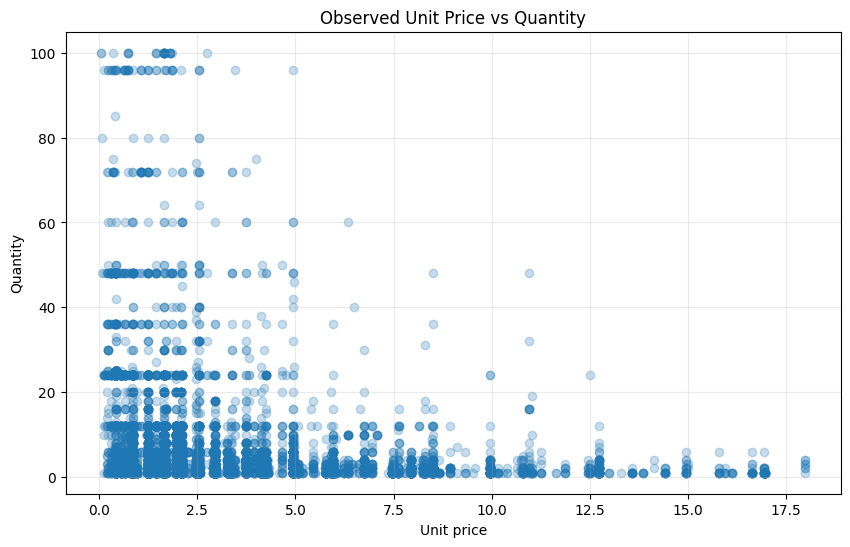

Pearson correlation: -0.0038


In [16]:
plot_sample = df.sample(
    n=min(10_000, len(df)),
    random_state=42
)

plot_sample = plot_sample[
    (plot_sample["quantity"] <= quantity_cap)
    & (plot_sample["unit_price"] <= price_cap)
]

plt.figure(figsize=(10, 6))
plt.scatter(
    plot_sample["unit_price"],
    plot_sample["quantity"],
    alpha=0.25
)
plt.title("Observed Unit Price vs Quantity")
plt.xlabel("Unit price")
plt.ylabel("Quantity")
plt.grid(alpha=0.25)
plt.show()

correlation = df[["unit_price", "quantity"]].corr().iloc[0, 1]
print(f"Pearson correlation: {correlation:.4f}")

## 8. Export EDA Outputs

The monthly and product-level summaries are exported to the reports directory so they can be reused in later analysis.

These are derived outputs and can be regenerated by running this notebook. The large transaction-level datasets should remain outside Git unless the team has approved a suitable data-storage approach.

In [17]:
monthly_path = REPORT_DIR / "monthly_sales_summary.csv"
product_path = REPORT_DIR / "product_price_summary.csv"

monthly_summary.to_csv(monthly_path, index=False)
product_summary.to_csv(product_path, index=False)

print("Saved:", monthly_path)
print("Saved:", product_path)

Saved: c:\intern_project\econocausal-dml\reports\monthly_sales_summary.csv
Saved: c:\intern_project\econocausal-dml\reports\product_price_summary.csv


## 9. Preliminary Conclusions

Complete this section after reviewing the notebook outputs.

- **Data quality:** Summarize the missing-value and duplicate checks.
- **Quantity distribution:** Describe the main pattern and any extreme values.
- **Price distribution:** Describe price concentration and skewness.
- **Monthly trends:** Identify any visible changes in transaction activity.
- **Price variation:** Report how many sufficiently observed products have multiple prices.
- **Causal limitations:** Identify important confounders that are unavailable or not yet measured.

### Next Steps
The next phase will define the causal estimand, treatment, outcome, and analysis unit. We will investigate whether the available data and observed price variation support a credible Double Machine Learning analysis before fitting the model.